# 08 · NEON label measurement model: probe shielding, label definition, high RH

**Scope.** Exploratory (review 3: GO for exploratory M1). HARV (humid forest) and CPER (semi-arid grassland), tower top, June–August 2023; CPER was chosen as the contrasting site on climate and coverage before any of its humidity data were read. The questions:
1. what the documentation says about the HMP155's shield and radiation error, and whether it applied in 2023;
2. how the probe–aspirated temperature disagreement depends on sunshine *and* wind;
3. whether probe heating reaches the probe dew point;
4. how the label candidates and their uncertainties behave;
5. what process produces the high-RH plateau.

No model is fitted and no visual information is used.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pypdf import PdfReader

from visual_hygrometry import neon, thermo

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (11, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 3)
MONTHS = ['2023-06', '2023-07', '2023-08']
SITES = {'HARV': -5, 'CPER': -7}  # UTC offset of local standard time
S = {site: neon.load_site(site, MONTHS) for site in SITES}
for site, off in SITES.items():
    S[site]['lst_hour'] = (S[site].index + pd.Timedelta(hours=off)).hour
    S[site]['day'] = S[site].index.tz_convert(f'Etc/GMT+{-off}').date
print({k: v.shape for k, v in S.items()})

{'HARV': (132480, 20), 'CPER': (132480, 20)}


## 1 · Documentary evidence

The humidity ATBD (NEON.DOC.000851, revision A 2015-09-03 and revision C 2022-05-16, downloaded from the NEON document API into `data/raw/docs/`) states in §6.1.1.2:
- the HMP155 sits in a **passive radiation shield**, one that "relies on ambient wind for ventilation";
- such shields can produce large positive temperature errors under strong sun and low wind;
- RH and dew point are affected through their temperature dependence;
- NEON could not yet quantify the resulting uncertainty;
- data would be flagged when wind is below and insolation above thresholds.

The cell checks these statements in both revisions rather than reproducing them.

In [2]:
docs = {v: re.sub(r'\s+', ' ', ' '.join(p.extract_text() for p in PdfReader(neon.RAW / 'docs' / f'NEON.DOC.000851{v}.pdf').pages)) for v in ['vA', 'vC']}
claims = {'passive radiation shield': r'housed inside of a passive radiation shield', 'ventilated by ambient wind': r'relies on ambient wind for ventilation',
          'positive error at low wind, high sun': r'large\s*,?\s*positive\s*,?\s*temperature errors if ambient wind speed is low and incoming solar radiation is high',
          'RH and dew point affected': r'relative humidity measurements.{0,80}also affected by the radiation induced error', 'not yet quantified': r'cannot accurately quantify',
          'planned wind/insolation flag': r'flagged if ambient wind speed is below a threshold and insolation is above a threshold'}
pd.DataFrame({v: {k: bool(re.search(p, t, flags=re.I)) for k, p in claims.items()} for v, t in docs.items()})

,vA,vC
passive radiation shield,True,True
ventilated by ambient wind,True,True
"positive error at low wind, high sun",True,True
RH and dew point affected,True,True
not yet quantified,True,True
planned wind/insolation flag,True,True


**Did the configuration apply in summer 2023?** Sensor-position records give the tower-top location of each probe and its validity period. The readme issue log lists the issues whose date range overlaps summer 2023. The published quality-metric variables show which tests exist.

In [3]:
pos = []
for site in SITES:
    for prod in ['DP1.00098.001', 'DP1.00003.001', 'DP1.00001.001']:
        f = next((neon.RAW / 'neon' / site / '2023-07' / prod / 'basic').glob('*sensor_positions*'))
        p = pd.read_csv(f, dtype={'HOR.VER': str})
        top = p[p['HOR.VER'].str.startswith('000') & p.referenceLocationIDEndDateTime.isna()].sort_values('zOffset').iloc[-1]  # current records only
        pos.append(dict(site=site, product=prod, position=top['HOR.VER'], location=top.sensorLocationDescription, z_m=top.zOffset,
                        valid_from=top.referenceLocationIDStartDateTime, valid_to=top.referenceLocationIDEndDateTime))
display(pd.DataFrame(pos))
readme = next((neon.RAW / 'neon' / 'HARV' / '2023-07' / 'DP1.00098.001' / 'basic').glob('*readme*')).read_text(errors='replace')
issues = re.findall(r'Issue Date: (\S+)\s*\nIssue: (.{0,90}).*?Date Range: (\S+) to (\S+)\s*\n\s*Location\(s\) Affected: (.{0,60})', readme, flags=re.S)
iss = pd.DataFrame(issues, columns=['issue_date', 'issue (first 90 characters)', 'from', 'to', 'locations'])
print('issues overlapping June-August 2023 at all/many sites or HARV/CPER:')
display(iss[(iss['to'] >= '2023-06-01') & (iss['from'] <= '2023-08-31') & iss.locations.str.contains('All|ALL|Many|HARV|CPER', regex=True)])
var = pd.read_csv(next((neon.RAW / 'neon' / 'HARV' / '2023-07' / 'DP1.00098.001' / 'expanded').glob('*variables*')))
tests = sorted({re.sub(r'(Fail|Pass|NA)QM$', '', n) for n in var.fieldName if n.startswith('RH') and n.endswith('QM')})
print('published RH quality tests:', tests, '| any radiation / wind / insolation test:', any(re.search('rad|wind|insol', t, re.I) for t in tests))

,site,product,position,location,z_m,valid_from,valid_to
0,HARV,DP1.00098.001,000.060,"Harvard Forest Relative Humidity, Tower",38.63,2010-01-01T00:00:00Z,NaN
1,HARV,DP1.00003.001,000.060,Harvard Forest Triple Aspirated Air Temperatur...,38.39,2021-09-27T00:00:00Z,NaN
2,HARV,DP1.00001.001,000.050,Harvard Forest 2D Wind L5,29.58,2021-09-27T00:00:00Z,NaN
3,CPER,DP1.00098.001,000.040,"Central Plains Relative Humidity, Tower",7.68,2010-01-01T00:00:00Z,NaN
4,CPER,DP1.00003.001,000.040,Central Plains Triple Aspirated Air Temperatur...,7.70,2010-01-01T00:00:00Z,NaN
5,CPER,DP1.00001.001,000.030,Central Plains 2D Wind L3,3.84,2010-01-01T00:00:00Z,NaN


issues overlapping June-August 2023 at all/many sites or HARV/CPER:


,issue_date,issue (first 90 characters),from,to,locations


published RH quality tests: ['RHAlphaQM', 'RHBetaQM', 'RHGap', 'RHNull', 'RHPersistence', 'RHRange', 'RHSensorError', 'RHSpike', 'RHValidCal'] | any radiation / wind / insolation test: False


## 2 · Availability and the RH gap at high humidity

In [4]:
rows = []
for site, s in S.items():
    for c in ['rh', 'td', 't_probe', 't_asp', 'sw', 'wind']:
        rows.append(dict(site=site, series=c, present=s[c].notna().mean(), present_and_qf0=(s[c].notna() & (s[f'{c}_qf'] == 0)).mean()))
    gap = s.rh.isna() & s.td.notna()
    rows.append(dict(site=site, series='RH blank, Td present', present=gap.mean(), present_and_qf0=np.nan))
display(pd.DataFrame(rows).pivot(index='series', columns='site'))
qm = pd.read_csv(next((neon.RAW / 'neon' / 'HARV' / '2023-07' / 'DP1.00098.001' / 'expanded').glob('*RH_1min*expanded*')))
blank = qm.RHMean.isna() & qm.dewTempMean.notna()
print(f'HARV July: {blank.sum()} blank-RH minutes with a dew point; share failing each test there:',
      qm.loc[blank, [c for c in qm if c.startswith('RH') and c.endswith('FailQM')]].mean().round(1).to_dict())

present        present_and_qf0       
site                       CPER   HARV            CPER   HARV
series                                                       
RH blank, Td present  4.604e-04  0.034             NaN    NaN
rh                    9.985e-01  0.957           0.987  0.956
sw                    9.978e-01  0.990           0.997  0.990
t_asp                 9.990e-01  0.990           0.998  0.990
t_probe               9.990e-01  0.990           0.999  0.990
td                    9.990e-01  0.990           0.997  0.990
wind                  9.993e-01  0.991           0.999  0.990

HARV July: 1347 blank-RH minutes with a dew point; share failing each test there: {'RHRangeFailQM': 0.0, 'RHPersistenceFailQM': 100.0, 'RHNullFailQM': 0.0, 'RHGapFailQM': 0.0, 'RHSpikeFailQM': 0.0, 'RHValidCalFailQM': nan, 'RHSensorErrorFailQM': 0.0}


At both sites, NEON blanks RH (flag 1) in some minutes where the dew point from the same probe passes QC. At HARV in July every such minute fails the **persistence** test and no other test. The RH is nearly constant there, which the test reads as a stuck sensor. §6 shows these minutes sit on the high-RH plateau, so **any label built from the published RH is missing not at random at the humid end**. A dew-point-based label is not.

## 3 · Probe − aspirated temperature against sunshine and wind

HARV: night mean +0.005 K | day mean +0.387 K | dT = +0.12 -0.008 SW/100 +0.156 (SW/100)/(u + 0.5)  R2 = 0.22
CPER: night mean -0.115 K | day mean +0.370 K | dT = +0.08 -0.002 SW/100 +0.209 (SW/100)/(u + 0.5)  R2 = 0.20


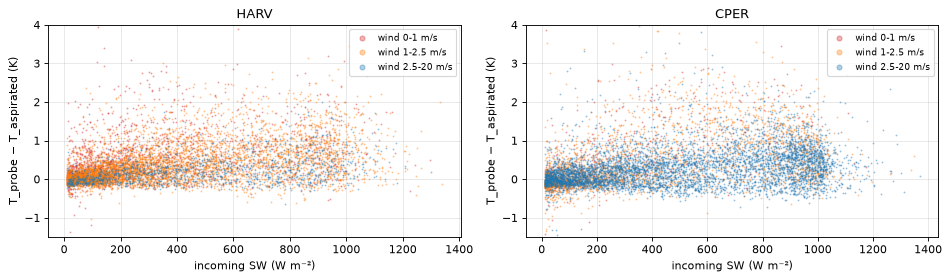

HARV: mean probe − aspirated (K) by SW (rows) and wind speed m/s (columns), daytime


wind,"(0, 1]","(1, 2]","(2, 3]","(3, 5]","(5, 20]"
sw,,,,,
"(10, 200]",0.289,0.128,0.040,0.035,0.041
"(200, 400]",0.727,0.402,0.262,0.146,0.090
"(400, 600]",0.832,0.560,0.375,0.194,0.112
"(600, 800]",0.885,0.670,0.434,0.243,0.141
"(800, 1400]",0.901,0.757,0.594,0.354,0.299


CPER: mean probe − aspirated (K) by SW (rows) and wind speed m/s (columns), daytime


wind,"(0, 1]","(1, 2]","(2, 3]","(3, 5]","(5, 20]"
sw,,,,,
"(10, 200]",0.171,0.052,0.081,0.075,0.055
"(200, 400]",0.665,0.468,0.327,0.262,0.141
"(400, 600]",1.214,0.950,0.631,0.347,0.160
"(600, 800]",1.259,1.052,0.892,0.460,0.258
"(800, 1400]",1.012,0.787,0.697,0.470,0.302


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
tabs = {}
for a, (site, s) in zip(ax, S.items()):
    ok = (s[['t_probe_qf', 't_asp_qf', 'sw_qf']] == 0).all(axis=1) & s[['t_probe', 't_asp', 'sw', 'wind']].notna().all(axis=1)
    d = s[ok].assign(dT=lambda x: x.t_probe - x.t_asp)
    day = d[d.sw > 10]
    tabs[site] = day.groupby([pd.cut(day.sw, [10, 200, 400, 600, 800, 1400]), pd.cut(day.wind, [0, 1, 2, 3, 5, 20])], observed=True).dT.mean().unstack()
    X = np.c_[np.ones(len(day)), day.sw / 100, day.sw / 100 / (day.wind + 0.5)]
    coef, *_ = np.linalg.lstsq(X, day.dT, rcond=None)
    r2 = 1 - np.var(day.dT - X @ coef) / np.var(day.dT)
    print(f'{site}: night mean {d.dT[d.sw <= 10].mean():+.3f} K | day mean {day.dT.mean():+.3f} K | '
          f'dT = {coef[0]:+.2f} {coef[1]:+.3f} SW/100 {coef[2]:+.3f} (SW/100)/(u + 0.5)  R2 = {r2:.2f}')
    for lo, hi, c in [(0, 1, 'C3'), (1, 2.5, 'C1'), (2.5, 20, 'C0')]:
        m = (day.wind >= lo) & (day.wind < hi)
        a.plot(day.sw[m][::9], day.dT[m][::9], '.', ms=1.5, alpha=.35, c=c, label=f'wind {lo}-{hi} m/s')
    a.set(title=site, xlabel='incoming SW (W m⁻²)', ylabel='T_probe − T_aspirated (K)', ylim=(-1.5, 4)); a.legend(fontsize=8, markerscale=6)
plt.tight_layout(); plt.show()
for site, t in tabs.items():
    print(f'{site}: mean probe − aspirated (K) by SW (rows) and wind speed m/s (columns), daytime'); display(t)

**Observation.** At both sites the daytime probe − aspirated difference rises with sunshine and falls with wind:

| above 800 W m⁻² (CPER: 600–800) | wind below 1 m/s | wind above 5 m/s |
|---|---|---|
| HARV | +0.90 K | +0.30 K |
| CPER | +1.26 K | +0.26 K |

At night the mean is +0.005 K at HARV and −0.115 K at CPER, which points to an inter-sensor offset of order 0.1 K that does not depend on sunshine. A heating index SW/(u + 0.5) explains about 20 % of the daytime variance, with coefficients +0.16 and +0.21 K per (100 W m⁻²)/(m s⁻¹).

**Interpretation.** This is the radiation-error signature the ATBD describes for a passive shield. Not all of the difference is error:
- the two probes measure air 6.5 m apart at HARV;
- wind is measured below the probes (HARV 29.6 m vs 38.6 m; CPER 3.8 m vs 7.7 m), so the true ventilation at the probe is not observed.

No published flag marks these conditions; the ATBD's planned wind/insolation flag does not appear among the published tests.

## 4 · Does probe heating reach the probe dew point?

If the RH element and the probe thermometer warm together, vapour pressure is unchanged and the reported dew point stays right while the probe temperature reads high. If heating is uneven, the dew point inherits an error too, which the ATBD allows for. The test uses sunshine transients (passing clouds, minute to minute, daytime): the probe − aspirated temperature difference must follow them; a heating-sensitive dew point would follow them as well.

In [6]:
rows = []
for site, s in S.items():
    valid = (s.sw > 10) & (s[['t_probe_qf', 't_asp_qf', 'td_qf']] == 0).all(axis=1) & s[['t_probe', 't_asp', 'td', 'sw']].notna().all(axis=1)
    dd = s[['t_probe', 't_asp', 'td', 'sw']].diff()[valid & valid.shift(1, fill_value=False)]
    dd['ddT'] = dd.t_probe - dd.t_asp
    big = dd.sw.abs() > 100
    for name, col in [('probe − aspirated T', 'ddT'), ('probe dew point', 'td'), ('aspirated T', 't_asp')]:
        rows.append(dict(site=site, series=name, minutes=len(dd), corr_with_dSW=np.corrcoef(dd.sw, dd[col])[0, 1], slope_K_per_100Wm2=np.polyfit(dd.sw, dd[col], 1)[0] * 100,
                         mean_abs_change_dSW_gt_100=dd[col][big].abs().mean(), mean_abs_change_dSW_le_100=dd[col][~big].abs().mean()))
pd.DataFrame(rows).set_index(['site', 'series'])

minutes  corr_with_dSW  slope_K_per_100Wm2  \
site series                                                            
HARV probe − aspirated T    74939      9.848e-04           2.188e-04   
     probe dew point        74939     -1.503e-02          -4.065e-03   
     aspirated T            74939     -3.990e-02          -4.982e-03   
CPER probe − aspirated T    75180     -1.570e-02          -4.646e-03   
     probe dew point        75180      1.497e-03           7.741e-04   
     aspirated T            75180      2.948e-03           7.445e-04   

                          mean_abs_change_dSW_gt_100  \
site series                                            
HARV probe − aspirated T                       0.142   
     probe dew point                           0.195   
     aspirated T                               0.107   
CPER probe − aspirated T                       0.175   
     probe dew point                           0.288   
     aspirated T                               0.164   

                          mean_abs_change_dSW_le_100  
site series                                           
HARV probe − aspirated T                       0.100  
     probe dew point                           0.138  
     aspirated T                               0.064  
CPER probe − aspirated T                       0.130  
     probe dew point                           0.244  
     aspirated T                               0.122

**Inconclusive.** Minute-to-minute changes of all three series are uncorrelated with shortwave changes (|r| < 0.04). Larger shortwave transients (> 100 W m⁻² per minute) coincide with larger changes in *every* series, the aspirated temperature included. They therefore mix real air changes with any sensor response, and the shield's thermal lag smears one-minute steps.

These data cannot show whether heating reaches the probe dew point. The leading label D_h therefore *assumes*, unverified, that the probe dew point carries no radiation error. The probe-temperature label stays a mandatory sensitivity analysis. A second humidity reference would test the assumption: the soil-array HMP155 at the same site (different height), or an aspirated or chilled-mirror hygrometer in the field pilot.

## 5 · Label candidates and their uncertainties

- `D_probe = T_probe − Td_probe`: independent of the conditioning thermometer, but it carries the shield's heating error.
- `D_h = T_asp − Td_probe`: the leading exploratory label.
- `RH_h = 100 e_s(Td_probe)/e_s(T_asp)`.

At fixed T_asp, `D_h` and `RH_h` are exact inverses of each other, so conditional information given T_asp is the same for either target, and the same as for `Td_probe` itself. What changes is agreement with NEON's published RH, which refers to the probe's own (warmer) temperature.

Uncertainties use NEON's expanded uncertainties (coverage factor 2): σ_Td = `dewTempExpUncert`/2, σ_Tasp = `tempTripleExpUncert`/2, and σ(D_h) = √(σ_Td² + σ_Tasp²) for independent units. The two terms are not fully separable. T_asp enters both the label and the conditioning temperature (a common-mode error of order σ_Tasp), and Td_probe inherits whatever heating its own probe suffers (§4).

In [7]:
rows, neg = [], {}
for site, s in S.items():
    d = s[(s[['td_qf', 't_asp_qf', 't_probe_qf']] == 0).all(axis=1) & s[['td', 't_asp', 't_probe']].notna().all(axis=1)].copy()
    d['D_probe'], d['D_h'] = d.t_probe - d.td, d.t_asp - d.td
    d['RH_h'] = thermo.rh_from_dewpoint(d.t_asp, d.td)
    d['sd_Dh'] = np.hypot(d.td_unc / 2, d.t_asp_unc / 2)
    d['z'] = d.D_h / d.sd_Dh
    S[site] = S[site].join(d[['D_probe', 'D_h', 'RH_h', 'sd_Dh']])
    neg[site] = d[d.D_h < 0]
    rows.append(dict(site=site, minutes=len(d), median_sd_Td=(d.td_unc / 2).median(), median_sd_Tasp=(d.t_asp_unc / 2).median(), median_sd_Dh=d.sd_Dh.median(),
                     D_h_negative=(d.D_h < 0).mean(), D_h_below_minus_2sd=(d.z < -2).mean(), min_D_h=d.D_h.min(),
                     RH_h_minus_RH_day=(d.RH_h - d.rh)[d.sw > 10].mean(), RH_h_minus_RH_night=(d.RH_h - d.rh)[d.sw <= 10].mean()))
display(pd.DataFrame(rows).set_index('site'))
for site, n in neg.items():
    if len(n):
        print(f'{site}: negative D_h minutes - local hour {np.bincount(n.lst_hour, minlength=24).argmax()} most common; daylit share {(n.sw > 10).mean():.0%}; '
              f'median wind {n.wind.median():.2f} m/s; median probe RH {n.rh.median():.1f} %; longest run {n.index.to_series().diff().ne(pd.Timedelta("1min")).cumsum().value_counts().max()} min')

,minutes,median_sd_Td,median_sd_Tasp,median_sd_Dh,D_h_negative,D_h_below_minus_2sd,min_D_h,RH_h_minus_RH_day,RH_h_minus_RH_night
site,,,,,,,,,
HARV,131065,0.157,0.072,0.171,0.001,2.899e-04,-0.831,1.378,-0.238
CPER,131961,0.191,0.042,0.197,0.015,7.267e-03,-2.064,0.747,-0.740


HARV: negative D_h minutes - local hour 2 most common; daylit share 33%; median wind 0.75 m/s; median probe RH 98.3 %; longest run 6 min
CPER: negative D_h minutes - local hour 5 most common; daylit share 43%; median wind 1.92 m/s; median probe RH 103.4 %; longest run 508 min


- **Uncertainty.** σ(D_h) ≈ 0.17 K (HARV) and 0.20 K (CPER), dominated by the dew-point term.
- **Negative D_h.** It occurs in 0.1 % (HARV) and 1.5 % (CPER) of minutes, and falls below −2σ in 0.03 % and 0.7 %.
  - HARV's cases are short (≤ 6 min) night-time events on the plateau (probe RH ≈ 98.3 %), compatible with measurement uncertainty.
  - CPER's are long runs during which the probe reports RH above 100 % (§6). Those values are physically impossible for free air and indicate a wetted probe.

  Nothing is clipped. Minutes with D_h < −2σ(D_h) are excluded as inconsistent and counted, and the rest are kept as observed.
- **RH_h vs published RH.** RH_h, relative to the aspirated temperature, exceeds the published probe RH by 1.4 (HARV) and 0.7 %RH (CPER) by day: the radiation error expressed in RH. At night it is lower by 0.2 and 0.7 %RH.
- **Scoring Td directly while conditioning on T_asp.** This is the same information as scoring D_h, because the map is exactly invertible at fixed T_asp. Ridge fits are not equivariant to that change of target, so notebook 10 checks numerically how much the operational contrast moves.

## 6 · High-RH measurement model

Three processes must be separated:
- **measurement uncertainty**: a noisy but unbiased reading;
- **physical saturation**: air at 100 %, which no reading should exceed except by error;
- **instrument censoring or clipping**: readings that cannot exceed a value.

A clip would put a mass of readings on one value. Saturation-related under-reading would show as a smooth pile-up whose ceiling varies. QC removal is visible directly in the flags.

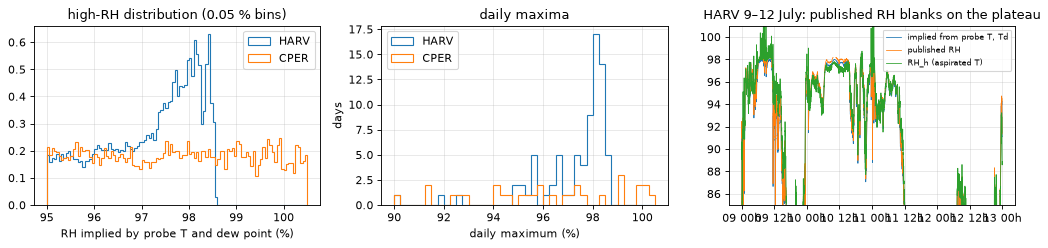

,implied_RH_ge_97,implied_RH_ge_98_3,max_implied,max_1Hz_RH,share_of_ge97_with_RH_blank,most_common_value_share,daily_max_sd,D_h_at_plateau_median
site,,,,,,,,
HARV,0.129,0.023,98.725,99.07,0.260,0.014,0.961,0.304
CPER,0.050,0.037,112.320,112.67,0.009,0.005,3.573,0.137


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
rows = []
for k, (site, s) in enumerate(S.items()):
    imp = thermo.rh_from_dewpoint(s.t_probe, s.td).where((s.td_qf == 0) & (s.t_probe_qf == 0))
    hi = imp[imp >= 95]
    ax[0].hist(hi, bins=np.arange(95, 100.51, 0.05), histtype='step', label=site, density=True)
    nmax = imp.groupby(s.day).max()
    ax[1].hist(nmax[nmax > 90], bins=np.arange(90, 100.51, 0.25), histtype='step', label=site)
    top = imp.round(2)[imp >= 97]
    rows.append(dict(site=site, implied_RH_ge_97=(imp >= 97).mean(), implied_RH_ge_98_3=(imp >= 98.3).mean(), max_implied=imp.max(), max_1Hz_RH=s.rh_max.max(),
                     share_of_ge97_with_RH_blank=s.rh[imp >= 97].isna().mean(), most_common_value_share=top.value_counts(normalize=True).iloc[0] if len(top) else np.nan,
                     daily_max_sd=nmax[nmax > 95].std(), D_h_at_plateau_median=s.D_h[imp >= 98].median()))
    if site == 'HARV':
        sub = s.loc['2023-07-09':'2023-07-12']
        ax[2].plot(sub.index, thermo.rh_from_dewpoint(sub.t_probe, sub.td), lw=.7, label='implied from probe T, Td')
        ax[2].plot(sub.index, sub.rh, lw=.7, label='published RH'); ax[2].plot(sub.index, sub.RH_h, lw=.7, label='RH_h (aspirated T)')
ax[0].set(xlabel='RH implied by probe T and dew point (%)', title='high-RH distribution (0.05 % bins)'); ax[0].legend()
ax[1].set(xlabel='daily maximum (%)', ylabel='days', title='daily maxima'); ax[1].legend()
ax[2].set(ylim=(85, 101), title='HARV 9–12 July: published RH blanks on the plateau'); ax[2].legend(fontsize=7)
ax[2].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d %Hh'))
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index('site')

**HARV.**
- **No clip.** The RH implied by the probe's temperature and dew point piles up smoothly below about 98.7 %, with a 1 Hz maximum of 99.07 %. No single value holds more than 1.4 % of the high readings, and the daily ceiling varies by about 1 %RH. That is no evidence of clipping.
- **QC removal.** 26 % of minutes with implied RH ≥ 97 % have their *published* RH blanked by the persistence test.
- **Aspirated reference.** It puts the plateau 0.3 K above the dew point, ≈ 98 % RH.
- **Not an instrument cap.** The same probe model at CPER reports values far above 100 %. Whether air 38 m above the HARV canopy rarely saturates, or this probe under-reads near saturation, cannot be decided without an independent saturation indicator.

In [9]:
for site, s in S.items():
    hi = s.rh > 100
    run = (hi != hi.shift()).cumsum()
    ep = s[hi].groupby(run[hi]).agg(minutes=('rh', 'size'), rh_max=('rh', 'max'))
    print(f'{site}: {len(ep)} episodes with published RH > 100 % ({ep.minutes.sum()} minutes, {hi.mean():.1%}); {int((ep.minutes >= 60).sum())} longer than 1 h; '
          f'longest {ep.minutes.max() if len(ep) else 0} min; max {s.rh.max():.1f} %; share of these minutes passing QC {(s.rh_qf[hi] == 0).mean() if hi.any() else np.nan:.0%}')

HARV: 0 episodes with published RH > 100 % (0 minutes, 0.0%); 0 longer than 1 h; longest 0 min; max 99.0 %; share of these minutes passing QC nan%
CPER: 43 episodes with published RH > 100 % (3062 minutes, 2.3%); 13 longer than 1 h; longest 642 min; max 112.7 %; share of these minutes passing QC 52%


**CPER.** RH > 100 % occurs in 43 episodes (3062 minutes, 2.3 % of the summer); 13 last over an hour, the longest 642 minutes overnight on 5–6 July, reaching 109 %. 52 % of these minutes pass QC. They are wetted-probe episodes, not air states.

**Measurement model adopted (exploratory, decision D-046).**
- No censoring process is verified at either site, so no censored likelihood is used. Values are kept as observed, with NEON's uncertainty.
- The label is D_h, from the dew point, which avoids the persistence-test gap that makes published RH missing-not-at-random at the humid end.
- Minutes with D_h < −2σ(D_h) are excluded as inconsistent and counted.
- Implied RH ≥ 98.3 % is a sensitivity *stratum*, not a censoring threshold.
- No fog or dew mechanism claims are made from these data.

## 7 · Summary

| question | finding | status |
|---|---|---|
| shield type | passive radiation shield per ATBD NEON.DOC.000851 rev A (2015) and rev C (2022), §6.1.1.2; position records current through summer 2023 at both sites | **documented** |
| radiation flag | described in the ATBD as planned; no radiation / wind / insolation test among published quality metrics | **absent** |
| radiation error | probe − aspirated up to +0.9 (HARV) and +1.3 K (CPER) at high sun and low wind, about +0.3 K above 5 m/s | measured; partly spatial |
| heating in the dew point | 1-min transient test confounded by real air changes | **unresolved** |
| label | D_h = T_asp − Td_probe leading; D_probe mandatory sensitivity; σ(D_h) ≈ 0.17–0.20 K | adopted (exploratory) |
| published RH at the humid end | blanked by the persistence test in 26 % of HARV minutes with implied RH ≥ 97 % | missing not at random; avoided by using Td |
| high-RH plateau (HARV) | smooth, variable ceiling ≈ 98.5–99 %, no clip | cause undetermined |
| supersaturated readings (CPER) | 2.3 % of minutes > 100 %, up to 112.7 %, 52 % passing QC | wetted probe; excluded via D_h < −2σ |
| censoring | not verified at either site | no censored likelihood |